# WEEK 7 - Feature Selection and PCA

## Dimensionality Reduction

In this week, feature selection and dimensionality reduction are performed
to identify important numerical features and reduce the number of dimensions
while retaining most of the useful information.

The main steps include:

- Correlation-based feature selection
- Multicollinearity inspection
- PCA (Principal Component Analysis)
- Explained Variance Analysis
- 2D PCA Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Dataset/feature_engineered_data.csv")

print("Feature engineered dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Feature engineered dataset loaded successfully!
Dataset shape: (30000, 30)
Missing values: 0


## Correlation-Based Feature Selection

Correlation analysis is used to identify strongly related numerical features.

Highly correlated features may contain redundant information and can lead
to multicollinearity.

Features with very high correlation are inspected before applying PCA.

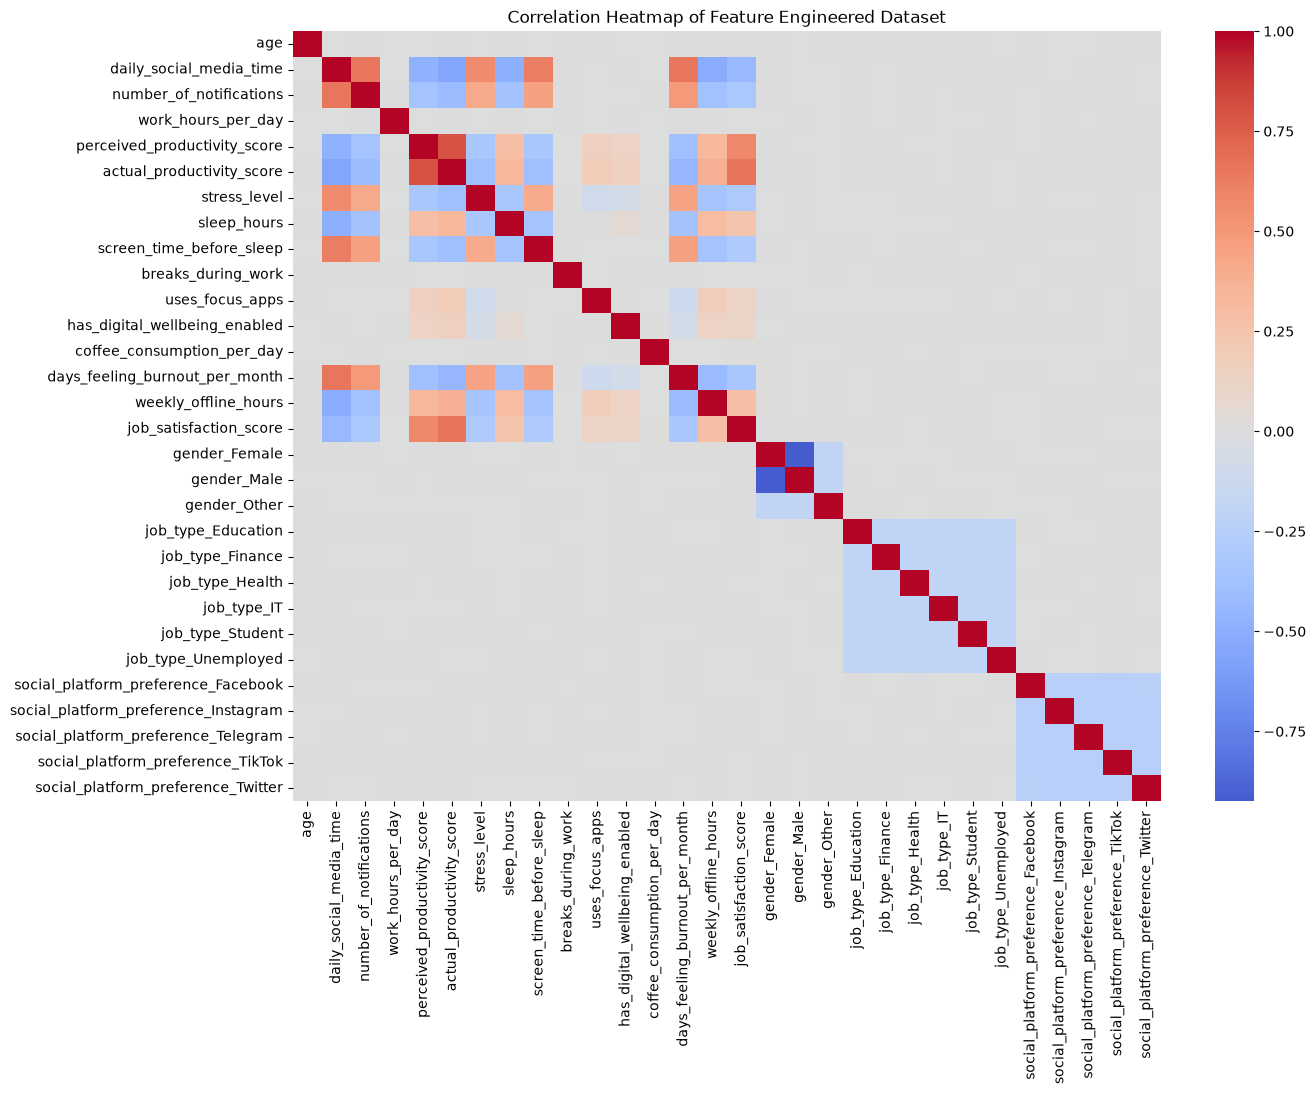

In [3]:
correlation_matrix = df.corr()

plt.figure(figsize=(14,10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Feature Engineered Dataset")

plt.show()

In [4]:
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlation_pairs = []

for column in upper_triangle.columns:
    for index in upper_triangle.index:
        value = upper_triangle.loc[index, column]

        if abs(value) > 0.80:
            high_correlation_pairs.append(
                [index, column, round(value, 2)]
            )

high_corr_df = pd.DataFrame(
    high_correlation_pairs,
    columns=["Feature 1", "Feature 2", "Correlation"]
)

high_corr_df

,Feature 1,Feature 2,Correlation
0,perceived_productivity_score,actual_productivity_score,0.80
1,gender_Female,gender_Male,-0.92


## Preparing Data for PCA

PCA requires numerical input.

Since the Week 6 dataset has already been scaled and encoded, it can
be directly used for dimensionality reduction.

In [5]:
X = df.copy()

print("PCA input shape:", X.shape)

PCA input shape: (30000, 30)


## Principal Component Analysis (PCA)

Principal Component Analysis reduces the number of dimensions in the dataset
while retaining as much important variance as possible.

The original features are transformed into new variables called
Principal Components.

In [6]:
pca = PCA()

pca_data = pca.fit_transform(X)

print("PCA completed successfully!")

PCA completed successfully!


In [8]:
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance):
    print(
        f"PC{i+1}: {variance:.4f} "
        f"({variance*100:.2f}%)"
    )

PC1: 0.2963 (29.63%)
PC2: 0.0751 (7.51%)
PC3: 0.0612 (6.12%)
PC4: 0.0606 (6.06%)
PC5: 0.0602 (6.02%)
PC6: 0.0595 (5.95%)
PC7: 0.0429 (4.29%)
PC8: 0.0403 (4.03%)
PC9: 0.0367 (3.67%)
PC10: 0.0326 (3.26%)
PC11: 0.0305 (3.05%)
PC12: 0.0290 (2.90%)
PC13: 0.0264 (2.64%)
PC14: 0.0151 (1.51%)
PC15: 0.0122 (1.22%)
PC16: 0.0121 (1.21%)
PC17: 0.0121 (1.21%)
PC18: 0.0120 (1.20%)
PC19: 0.0117 (1.17%)
PC20: 0.0113 (1.13%)
PC21: 0.0101 (1.01%)
PC22: 0.0101 (1.01%)
PC23: 0.0101 (1.01%)
PC24: 0.0100 (1.00%)
PC25: 0.0099 (0.99%)
PC26: 0.0086 (0.86%)
PC27: 0.0034 (0.34%)
PC28: 0.0000 (0.00%)
PC29: 0.0000 (0.00%)
PC30: 0.0000 (0.00%)


## Explained Variance Visualization

The explained variance ratio is plotted to understand how much information
is retained by each principal component.

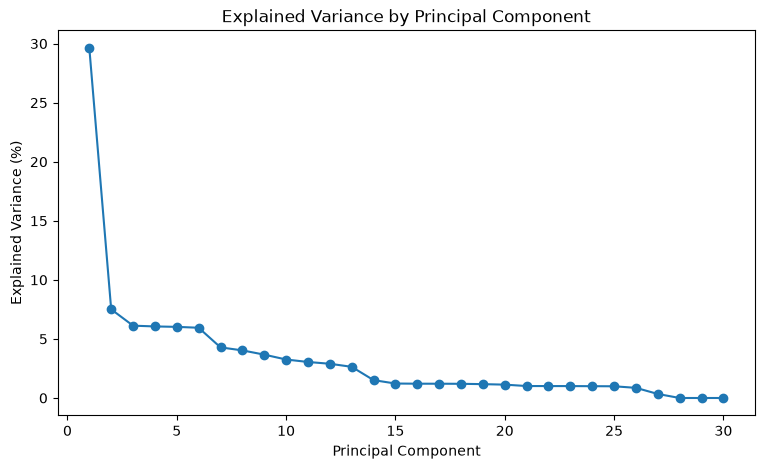

In [9]:
plt.figure(figsize=(9,5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance * 100,
    marker="o"
)

plt.title("Explained Variance by Principal Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")

plt.show()

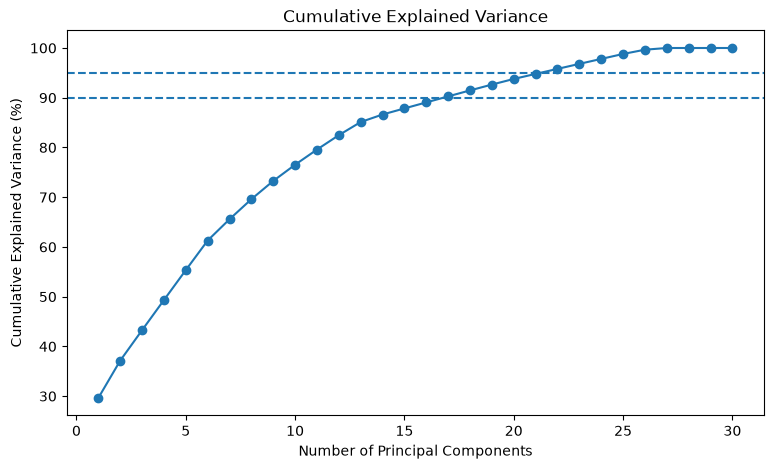

In [10]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(9,5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.axhline(y=90, linestyle="--")
plt.axhline(y=95, linestyle="--")

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")

plt.show()

In [11]:
components_90 = np.argmax(
    cumulative_variance >= 0.90
) + 1

components_95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

print(
    "Components required for 90% variance:",
    components_90
)

print(
    "Components required for 95% variance:",
    components_95
)

Components required for 90% variance: 17
Components required for 95% variance: 22


In [12]:
components_90 = np.argmax(
    cumulative_variance >= 0.90
) + 1

components_95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

print(
    "Components required for 90% variance:",
    components_90
)

print(
    "Components required for 95% variance:",
    components_95
)

Components required for 90% variance: 17
Components required for 95% variance: 22


In [13]:
pca_2d = PCA(n_components=2)

pca_2d_data = pca_2d.fit_transform(X)

pca_2d_df = pd.DataFrame(
    pca_2d_data,
    columns=["PC1", "PC2"]
)

pca_2d_df.head()

,PC1,PC2
0,2.099283,0.572639
1,-0.449520,0.648874
2,-1.312961,0.638913
3,0.933671,-0.819624
4,-0.429358,-1.562734


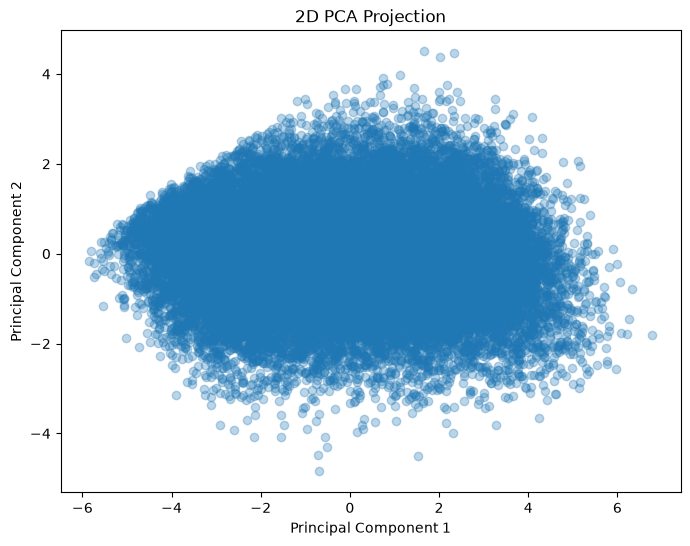

In [14]:
plt.figure(figsize=(8,6))

plt.scatter(
    pca_2d_df["PC1"],
    pca_2d_df["PC2"],
    alpha=0.3
)

plt.title("2D PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

### Observation

The 2D PCA plot represents the high-dimensional dataset using only the
first two principal components.

Each point represents one observation after dimensionality reduction.

The plot helps visualize the overall spread, structure and possible
grouping patterns present in the transformed dataset.

## 3D PCA Visualization

A 3D PCA plot is used to visualize the dataset using the first three
principal components.

This provides a better view of the structure and possible groupings
in the reduced feature space.

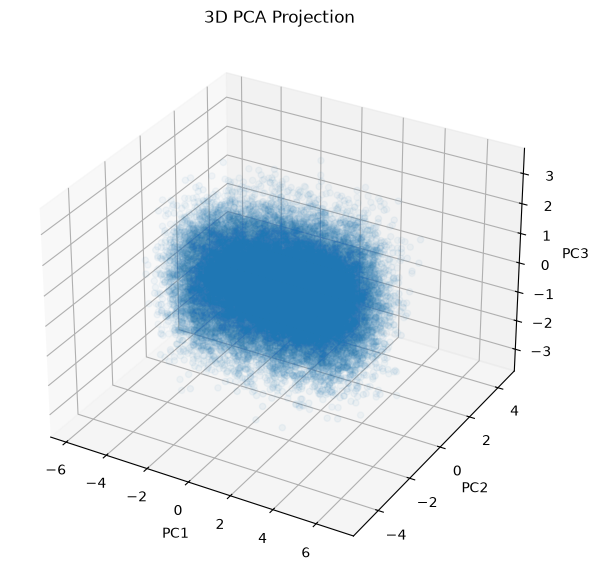

In [15]:
from mpl_toolkits.mplot3d import Axes3D

pca_3d = PCA(n_components=3)

pca_3d_data = pca_3d.fit_transform(X)

pca_3d_df = pd.DataFrame(
    pca_3d_data,
    columns=["PC1", "PC2", "PC3"]
)

fig = plt.figure(figsize=(9,7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    pca_3d_df["PC1"],
    pca_3d_df["PC2"],
    pca_3d_df["PC3"],
    alpha=0.25
)

ax.set_title("3D PCA Projection")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

plt.show()

### Observation

The 3D PCA plot represents the original high-dimensional dataset using
only three principal components.

The visualization helps examine the overall spread of observations and
identify possible grouping or clustering patterns in the reduced space.

In [16]:
pca_summary = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

pca_summary.head(10)

,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,29.629400,29.629400
1,PC2,7.506240,37.135640
2,PC3,6.122782,43.258422
3,PC4,6.058382,49.316805
4,PC5,6.021926,55.338730
5,PC6,5.946754,61.285484
6,PC7,4.285102,65.570586
7,PC8,4.030004,69.600590
8,PC9,3.671044,73.271634
9,PC10,3.258249,76.529883


In [17]:
final_pca = PCA(n_components=components_90)

final_pca_data = final_pca.fit_transform(X)

final_pca_df = pd.DataFrame(
    final_pca_data,
    columns=[
        f"PC{i+1}"
        for i in range(components_90)
    ]
)

print("Original dimensions:", X.shape[1])
print("Reduced dimensions:", final_pca_df.shape[1])
print(
    "Variance retained:",
    round(
        final_pca.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

Original dimensions: 30
Reduced dimensions: 17
Variance retained: 90.27 %


In [18]:
final_pca_df.to_csv(
    "Dataset/pca_transformed_data.csv",
    index=False
)

print("PCA transformed dataset saved successfully!")

PCA transformed dataset saved successfully!


## Week 7 Summary

- Correlation analysis was performed to identify strongly related features.
- Highly correlated feature pairs were inspected for possible redundancy.
- Principal Component Analysis (PCA) was applied for dimensionality reduction.
- Explained variance was calculated for every principal component.
- Cumulative explained variance was used to determine the number of components
  required to retain 90% and 95% of the original information.
- The dataset was visualized using 2D and 3D PCA projections.
- A reduced PCA dataset retaining approximately 90% of the variance was created.
- The PCA-transformed dataset was saved for further analysis and dashboard development.